# MiniReasoner: Model Evaluation & Benchmarking

This notebook evaluates trained **MiniReasoner RoPE** checkpoints downloaded from **Azure Blob Storage** (`minireasoner`) or loaded from a local `.pt` file (see [COOKBOOK.md](../COOKBOOK.md)).

### Key Capabilities:
- **Device-Agnostic Support**: Runs cleanly on **CPU** (FP32) and **CUDA GPU** (BF16 on Ampere+ / FP32 otherwise).
- **Automatic Active Run Selection**: Discovers runs under `checkpoints/Shared/MiniReasoner/` in Azure Blob Storage, deprioritizes/filters deleted Databricks MLflow runs when configured, selects the newest active run (or an explicit `RUN_ID`), downloads the latest checkpoint (`CHECKPOINT_ALIAS = "latest"` by default), and caches checkpoints under `checkpoints/<run_id>/`.
- **RoPE Architecture & Convergence Analysis**: Inspects the 32.05M-parameter RoPE configuration (`context_length = 1,024`) and plots validation loss, interval-mean train loss, and LR schedule across training steps.
- **Held-Out `SimpleStories` Test Evaluation**: Scores unseen stories from the reserved published `test` split for **Test Loss**, **Perplexity**, **Bits-Per-Byte (`BPB`)**, and **RoPE Context Scaling (`1–256` vs `257–512` vs `513–1,024`)**.
- **Story Cloze 4-Choice Accuracy (`story_mc_acc`)**: HellaSwag-style length-normalized log-likelihood evaluation on unseen test stories.
- **Qualitative Generation, Pre-SFT Arithmetic Baseline, & Throughput**: Tests greedy decoding, nucleus sampling, long-context RoPE prompts (within the `1,024`-token window), 1–2 digit arithmetic accuracy, and `tok/s` speed.

## 1. Project Environment Setup
Load environment variables (Azure Blob Storage, Databricks MLflow, optional `HF_TOKEN`), locate the repository root, and configure `sys.path`.

In [13]:
import os
import sys
from pathlib import Path
from dotenv import load_dotenv

# Locate MiniReasoner repository root
working_dir = Path.cwd().resolve()
project_root = next(
    (path for path in (working_dir, *working_dir.parents)
     if (path / "src" / "train.py").is_file() and (path / "pyproject.toml").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook inside the MiniReasoner repository.")

load_dotenv(project_root / ".env")
print(f"Project root located at: {project_root}")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

Project root located at: C:\Users\sampa\Dev\MiniReasoner


## 2. Hardware & Device Configuration (CPU / GPU Compatibility)
Inference automatically detects whether a CUDA GPU is available (`DEVICE_PREFERENCE = "auto"`), or you can force `"cpu"` / `"cuda"`:
- **CUDA GPU**: Uses native BF16 on Ampere+ (A30, A100, RTX 30/40xx) or FP32 on older GPUs, scaling evaluation sample counts up automatically.
- **CPU**: Runs cleanly in Float32 without requiring CUDA drivers.

In [14]:
import torch

# Device selection: 'auto' (preferred), 'cuda', or 'cpu'
DEVICE_PREFERENCE = "auto"

if DEVICE_PREFERENCE == "auto":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
elif DEVICE_PREFERENCE in ("cuda", "cpu"):
    if DEVICE_PREFERENCE == "cuda" and not torch.cuda.is_available():
        print("Notice: CUDA requested but unavailable on this system. Falling back to CPU.")
        device = torch.device("cpu")
    else:
        device = torch.device(DEVICE_PREFERENCE)
else:
    raise ValueError(f"Unknown device preference: {DEVICE_PREFERENCE}")

print("=" * 60)
print(f"ACTIVE EXECUTION DEVICE: {device.type.upper()}")
print("=" * 60)

if device.type == "cuda":
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    cuda_cap = torch.cuda.get_device_capability(0)
    bf16_supported = torch.cuda.is_bf16_supported() and cuda_cap[0] >= 8
    dtype = torch.bfloat16 if bf16_supported else torch.float32
    print(f"GPU Hardware:       {gpu_name}")
    print(f"Total VRAM:         {vram_gb:.2f} GB")
    print(f"Compute Capability: {cuda_cap[0]}.{cuda_cap[1]}")
    print(f"Inference Dtype:    {dtype}")
else:
    dtype = torch.float32
    num_threads = torch.get_num_threads()
    print(f"CPU Threads:        {num_threads}")
    print("Inference Dtype:    torch.float32")
    print("Mode:               Portable CPU Inference")
print("=" * 60)

ACTIVE EXECUTION DEVICE: CPU
CPU Threads:        4
Inference Dtype:    torch.float32
Mode:               Portable CPU Inference


## 3. Discover & Retrieve Model Checkpoint from Azure Blob Storage
MiniReasoner checkpoints live under `checkpoints/Shared/MiniReasoner/<run_id>/` in Azure Blob Storage.

- Leave `RUN_ID = None` to auto-select the newest **active** run (runs deleted in Databricks MLflow are skipped automatically when Databricks credentials are present).
- Set `CHECKPOINT_ALIAS = "latest"` (default, highest step), `"best"` (lowest validation loss), or `"step-N"`.
- Set `LOCAL_CHECKPOINT = "path/to/file.pt"` for offline evaluation.

In [15]:
import re
from src.azure_blob import container_client
from src.checkpoint_store import CheckpointStore, _FILENAME, experiment_checkpoint_prefix
from src.settings import AZURE_CONTAINER, MLFLOW_EXPERIMENT

# Configuration overrides
RUN_ID = None                # Set to an MLflow run ID, or None to auto-select the newest active run
CHECKPOINT_ALIAS = "latest"  # 'latest' (highest step), 'best' (lowest val loss), or 'step-N'
LOCAL_CHECKPOINT = None      # Optional path to a local .pt file for offline evaluation

checkpoints_dir = project_root / "checkpoints"
checkpoints_dir.mkdir(parents=True, exist_ok=True)
best_snapshot = None

if LOCAL_CHECKPOINT is not None:
    cached_checkpoint_path = Path(LOCAL_CHECKPOINT).expanduser().resolve()
    if not cached_checkpoint_path.is_file():
        raise FileNotFoundError(f"Local checkpoint not found: {cached_checkpoint_path}")
    run_id = cached_checkpoint_path.parent.name
    print(f"Using offline local checkpoint: {cached_checkpoint_path}")
else:
    exp_prefix = experiment_checkpoint_prefix(MLFLOW_EXPERIMENT)
    container = container_client(AZURE_CONTAINER)

    if RUN_ID is None:
        runs_info = {}
        run_pattern = re.compile(rf"^{re.escape(exp_prefix)}([A-Za-z0-9_-]+)/([^/]+)$")
        for blob in container.list_blobs(name_starts_with=exp_prefix):
            match = run_pattern.match(blob.name)
            if not match:
                continue
            rid, fname = match.groups()
            if not _FILENAME.fullmatch(fname):
                continue
            entry = runs_info.setdefault(rid, {"count": 0, "last_modified": blob.last_modified})
            entry["count"] += 1
            if blob.last_modified and (entry["last_modified"] is None or blob.last_modified > entry["last_modified"]):
                entry["last_modified"] = blob.last_modified

        if not runs_info:
            raise FileNotFoundError(f"No checkpoints found under {exp_prefix} in Azure container '{AZURE_CONTAINER}'.")

        # Prefer runs that are active in Databricks MLflow when credentials are configured
        mlflow_states = {}
        if os.getenv("DATABRICKS_HOST", "").strip() and os.getenv("DATABRICKS_TOKEN", "").strip():
            try:
                import mlflow
                from mlflow import MlflowClient
                mlflow.set_tracking_uri("databricks")
                client = MlflowClient(tracking_uri="databricks")
                for rid in runs_info:
                    try:
                        mlflow_states[rid] = str(client.get_run(rid).info.lifecycle_stage).lower()
                    except Exception:
                        mlflow_states[rid] = "unknown"
            except Exception:
                pass

        discovered = sorted(
            runs_info.items(),
            key=lambda kv: (
                1 if mlflow_states.get(kv[0], "active") == "active" else 0,
                kv[1]["last_modified"].timestamp() if kv[1]["last_modified"] else 0.0,
            ),
            reverse=True,
        )
        print(f"Discovered {len(discovered)} run(s) in Azure container '{AZURE_CONTAINER}':\n")
        print(f"{'Run ID':<36}{'MLflow State':<14}{'Snapshots':<12}{'Last Updated (UTC)'}")
        print("-" * 84)
        for rid, info in discovered:
            ts = info["last_modified"].strftime("%Y-%m-%d %H:%M:%S") if info["last_modified"] else "N/A"
            st = mlflow_states.get(rid, "unverified")
            print(f"{rid:<36}{st:<14}{info['count']:<12}{ts}")
        run_id = discovered[0][0]
        print(f"\nAuto-selected run: {run_id}")
    else:
        run_id = RUN_ID

    store = CheckpointStore(AZURE_CONTAINER, run_id)
    versions = store._versions()
    if not versions:
        raise FileNotFoundError(f"No valid checkpoints found for run {run_id!r} in {store.location}.")

    print(f"\nTop checkpoints by validation loss for run {run_id} ({len(versions)} total):\n")
    print(f"{'Rank':<6}{'Step':<8}{'Val Loss':<12}{'Train Mean':<12}{'Filename'}")
    print("-" * 85)
    for i, snap in enumerate(versions[:5], start=1):
        print(f"#{i:<5}{snap.step:<8}{snap.val_loss:<12.4f}{snap.train_loss_interval_mean:<12.4f}{snap.name[:45]}...")

    if CHECKPOINT_ALIAS == "best":
        target_snapshot = versions[0]
    elif CHECKPOINT_ALIAS == "latest":
        target_snapshot = max(versions, key=lambda item: item.step)
    elif alias_match := re.fullmatch(r"step-(\d+)", CHECKPOINT_ALIAS):
        step_num = int(alias_match[1])
        target_snapshot = next((item for item in versions if item.step == step_num), None)
        if target_snapshot is None:
            raise FileNotFoundError(f"Step {step_num} not found in run {run_id}.")
    else:
        raise ValueError("CHECKPOINT_ALIAS must be 'best', 'latest', or 'step-N'.")

    best_snapshot = target_snapshot
    latest_snap = max(versions, key=lambda item: item.step)
    print(f"\n--> Selected ({CHECKPOINT_ALIAS}): Step {target_snapshot.step:,} | Val Loss: {target_snapshot.val_loss:.4f} | Train Mean: {target_snapshot.train_loss_interval_mean:.4f}")
    if latest_snap.step != target_snapshot.step:
        print(f"    Latest step in run: Step {latest_snap.step:,} | Val Loss: {latest_snap.val_loss:.4f} | Train Mean: {latest_snap.train_loss_interval_mean:.4f}")

    # Run-scoped local cache so checkpoints from different runs never collide
    run_cache_dir = checkpoints_dir / run_id
    run_cache_dir.mkdir(parents=True, exist_ok=True)
    cached_checkpoint_path = run_cache_dir / f"{CHECKPOINT_ALIAS}_step_{target_snapshot.step}_{target_snapshot.sha256[:8]}.pt"

    if not cached_checkpoint_path.is_file():
        print(f"Downloading checkpoint from Azure to {cached_checkpoint_path}...")
        store.download(CHECKPOINT_ALIAS, cached_checkpoint_path)
        print("Download complete and verified via SHA256 checksum!")
    else:
        size_mb = cached_checkpoint_path.stat().st_size / (1024 * 1024)
        print(f"Using locally cached checkpoint: {cached_checkpoint_path} ({size_mb:.2f} MB)")

Discovered 3 run(s) in Azure container 'minireasoner':

Run ID                              MLflow State  Snapshots   Last Updated (UTC)
------------------------------------------------------------------------------------
23a72f3aa8d6487ca401b92b22ae229c    active        53          2026-11-24 19:09:03
655ddf770790468d988bbb0375fd5aa4    active        48          2026-11-24 09:22:26
c26cf6e5ffc749e69b298d27f33ca243    deleted       4           2026-11-24 15:11:38

Auto-selected run: 23a72f3aa8d6487ca401b92b22ae229c

Top checkpoints by validation loss for run 23a72f3aa8d6487ca401b92b22ae229c (53 total):

Rank  Step    Val Loss    Train Mean  Filename
-------------------------------------------------------------------------------------
#1    25000   1.1302      1.1327      step-25000_val-1.130212310741517_train-1.1326...
#2    26047   1.1303      1.1231      step-26047_val-1.1303457730208912_train-1.123...
#3    26000   1.1315      1.1296      step-26000_val-1.1315013859334513_train-1.12

## 4. Load Checkpoint and Inspect Model Architecture
Load the weights, `GPTConfig`, and embedded Byte-Level BPE `tokenizer_json` onto the active hardware device (`cpu` or `cuda`).

In [16]:
from tokenizers import Tokenizer
from src.model import GPT, GPTConfig
from src.train import load_checkpoint
from src.tokenizer import EOS

print(f"Loading checkpoint weights from: {cached_checkpoint_path}")
checkpoint = load_checkpoint(cached_checkpoint_path)

tokenizer = Tokenizer.from_str(checkpoint["tokenizer_json"])
model_config = GPTConfig(**checkpoint["model_config"])

model = GPT(model_config).to(device).eval()
model.load_state_dict(checkpoint["model"])
if device.type == "cuda" and dtype == torch.bfloat16:
    model = model.to(dtype=torch.bfloat16)

total_params = sum(p.numel() for p in model.parameters())
wte_params = model.transformer.wte.weight.numel()
blocks_params = sum(p.numel() for p in model.transformer.h.parameters())
ln_f_params = sum(p.numel() for p in model.transformer.ln_f.parameters())
head_dim = model_config.n_embd // model_config.n_head
pos_desc = f"RoPE (theta={model_config.rope_theta:g}, head_dim={head_dim})" if model_config.pos_encoding == "rope" else model_config.pos_encoding

print("\n" + "=" * 58)
print("MINIREASONER MODEL ARCHITECTURE")
print("=" * 58)
print(f"Positional Encoding:        {pos_desc}")
print(f"Transformer Layers (Blocks): {model_config.n_layer}")
print(f"Attention Heads:            {model_config.n_head} ({head_dim} dim/head)")
print(f"Embedding Dimension:        {model_config.n_embd}")
print(f"Context Window Length:      {model_config.context_length:,} tokens")
print(f"Vocabulary Size:            {model_config.vocab_size:,} tokens")
print(f"Total Parameters:           {total_params:,} (~{total_params / 1e6:.2f}M)")
print(f"Token Embeddings (tied):    {wte_params:,}")
print(f"Transformer Core (Blocks):  {blocks_params:,}")
print(f"Final LayerNorm:            {ln_f_params:,}")
print(f"EOS Token:                  '{EOS}' (ID: {tokenizer.token_to_id(EOS)})")
print(f"Checkpoint Training Step:   {checkpoint.get('step', best_snapshot.step if best_snapshot else 0):,}")
print(f"Active Device / Dtype:      {device.type.upper()} / {dtype}")
print("=" * 58)

Loading checkpoint weights from: C:\Users\sampa\Dev\MiniReasoner\checkpoints\23a72f3aa8d6487ca401b92b22ae229c\latest_step_26047_095810fa.pt

MINIREASONER MODEL ARCHITECTURE
Positional Encoding:        RoPE (theta=10000, head_dim=64)
Transformer Layers (Blocks): 10
Attention Heads:            8 (64 dim/head)
Embedding Dimension:        512
Context Window Length:      1,024 tokens
Vocabulary Size:            1,024 tokens
Total Parameters:           32,049,152 (~32.05M)
Token Embeddings (tied):    524,288
Transformer Core (Blocks):  31,523,840
Final LayerNorm:            1,024
EOS Token:                  '<|eos|>' (ID: 0)
Checkpoint Training Step:   26,047
Active Device / Dtype:      CPU / torch.float32


## 5. Pre-Training Loss Curve & Learning Rate Analysis
Plot the validation loss, interval-mean training loss, and warmup/cosine learning rate schedule logged inside the checkpoint.

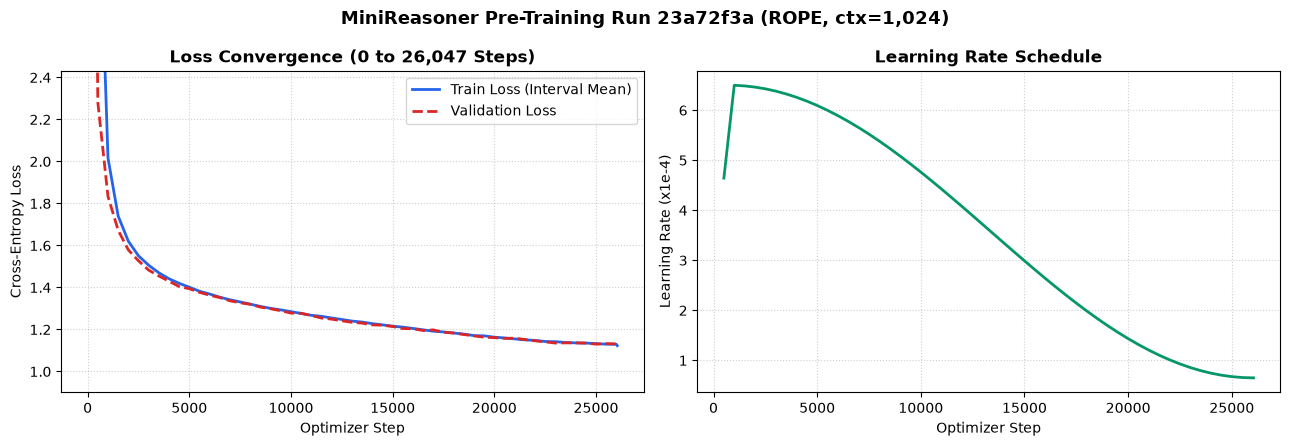

Initial Validation Loss: 7.0470 (Step 0)
Latest Logged Val Loss:  1.1303 (Step 26,047)
Best Validation Loss:    1.1302 (Step 25,000)
Net Loss Improvement:    5.9168
Mean Train Throughput:   137,848 tok/s


In [17]:
import matplotlib.pyplot as plt

metrics_history = checkpoint.get("metrics", [])

if metrics_history:
    val_points = [(m["step"], m["val_loss"]) for m in metrics_history if m.get("val_loss") is not None]
    train_points = [(m["step"], m["train_loss_interval_mean"]) for m in metrics_history if m.get("train_loss_interval_mean") is not None]
    lr_points = [(m["step"], m["lr"]) for m in metrics_history if m.get("lr") is not None]
    tps_vals = [m["train_tokens_per_second"] for m in metrics_history if m.get("train_tokens_per_second") is not None]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)
    if train_points:
        ax1.plot([s for s, _ in train_points], [v for _, v in train_points], label="Train Loss (Interval Mean)", color="#2563eb", linewidth=2)
    if val_points:
        ax1.plot([s for s, _ in val_points], [v for _, v in val_points], label="Validation Loss", color="#dc2626", linewidth=2, linestyle="--")
    max_step = max((m["step"] for m in metrics_history), default=0)
    ax1.set_title(f"Loss Convergence (0 to {max_step:,} Steps)", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Optimizer Step")
    ax1.set_ylabel("Cross-Entropy Loss")
    ax1.set_ylim(bottom=0.9, top=min(3.6, max((v for _, v in val_points[1:]), default=3.6) + 0.15))
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend()

    if lr_points:
        ax2.plot([s for s, _ in lr_points], [v * 1e4 for _, v in lr_points], color="#059669", linewidth=2)
        ax2.set_title("Learning Rate Schedule", fontsize=12, fontweight="bold")
        ax2.set_xlabel("Optimizer Step")
        ax2.set_ylabel("Learning Rate (x1e-4)")
        ax2.grid(True, linestyle=":", alpha=0.6)

    fig.suptitle(f"MiniReasoner Pre-Training Run {run_id[:8]} ({model_config.pos_encoding.upper()}, ctx={model_config.context_length:,})", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    if val_points:
        print(f"Initial Validation Loss: {val_points[0][1]:.4f} (Step {val_points[0][0]:,})")
        print(f"Latest Logged Val Loss:  {val_points[-1][1]:.4f} (Step {val_points[-1][0]:,})")
        best_val_step, best_val_loss = min(val_points, key=lambda x: x[1])
        print(f"Best Validation Loss:    {best_val_loss:.4f} (Step {best_val_step:,})")
        print(f"Net Loss Improvement:    {val_points[0][1] - best_val_loss:.4f}")
    if tps_vals:
        print(f"Mean Train Throughput:   {sum(tps_vals) / len(tps_vals):,.0f} tok/s")
elif best_snapshot is not None:
    print(f"Step {best_snapshot.step:,}: Validation Loss = {best_snapshot.val_loss:.4f}, Train Mean = {best_snapshot.train_loss_interval_mean:.4f}")

## 6. Device-Agnostic Generation Engine
Inference works identically on **both CPU (FP32) and CUDA GPU (BF16/FP32)** with FP32 logit sampling and automatic cropping to `model.config.context_length` (`1,024`).

In [18]:
import time
from typing import Dict, Any
from src.generate import prepare_prompt_tokens

@torch.inference_mode()
def generate(
    model: torch.nn.Module,
    tokenizer: Tokenizer,
    prompt: str,
    max_new_tokens: int = 150,
    temperature: float = 0.0,
    top_k: int = 50,
    top_p: float = 0.9,
    repetition_penalty: float = 1.0,
    device: torch.device = device,
) -> Dict[str, Any]:
    model.eval()
    eos_id = tokenizer.token_to_id(EOS)
    context_length = model.config.context_length
    ids = prepare_prompt_tokens(tokenizer, prompt, context_length)

    generated_tokens = []
    start_time = time.perf_counter()

    for _ in range(max_new_tokens):
        input_window = ids[-context_length:]
        x = torch.tensor([input_window], dtype=torch.long, device=device)

        logits = model(x)[0, -1].float()

        if repetition_penalty != 1.0:
            for prev_token in set(input_window):
                if logits[prev_token] < 0:
                    logits[prev_token] *= repetition_penalty
                else:
                    logits[prev_token] /= repetition_penalty

        if temperature <= 0.0 or top_k == 1:
            next_token_id = torch.argmax(logits).item()
        else:
            scaled_logits = logits / temperature

            if top_k > 0:
                v, _ = torch.topk(scaled_logits, min(top_k, scaled_logits.size(-1)))
                scaled_logits[scaled_logits < v[-1]] = -float("Inf")

            if 0.0 < top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(scaled_logits, descending=True)
                cumulative_probs = torch.cumsum(torch.softmax(sorted_logits, dim=-1), dim=-1)

                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
                sorted_indices_to_remove[..., 0] = 0

                indices_to_remove = sorted_indices[sorted_indices_to_remove]
                scaled_logits[indices_to_remove] = -float("Inf")

            probs = torch.softmax(scaled_logits, dim=-1)
            next_token_id = torch.multinomial(probs, num_samples=1).item()

        if next_token_id == eos_id:
            break

        ids.append(next_token_id)
        generated_tokens.append(next_token_id)

    elapsed_time = time.perf_counter() - start_time
    completion_text = tokenizer.decode(generated_tokens)
    tokens_per_sec = len(generated_tokens) / elapsed_time if elapsed_time > 0 else 0.0

    return {
        "prompt": prompt,
        "completion": completion_text,
        "full_text": prompt + completion_text,
        "tokens_generated": len(generated_tokens),
        "elapsed_seconds": elapsed_time,
        "tokens_per_second": tokens_per_sec,
        "device": device.type,
    }

print("Device-agnostic generator ready.")

Device-agnostic generator ready.


## 7. Held-Out `SimpleStories` Test Split: Perplexity, Bits-Per-Byte (`BPB`), & RoPE Position Scaling
We score unseen stories from the published **`SimpleStories/SimpleStories` `test` split** (skipping if unavailable):
- **Test Loss & Perplexity** ($\text{PPL} = \exp(\mathcal{L})$) per token.
- **Bits-Per-Byte (`BPB`)**: $\text{BPB} = \frac{\sum \text{NLL}_{\text{nats}}}{\ln(2) \cdot \text{predicted\_bytes}}$ — tokenizer-invariant metric allowing direct comparison against researchers using `4k`, `32k`, or `50k` vocabularies.
- **Position-Bucket Scaling (`1–256` vs `257–512` vs `513–1,024`)**: Tracks RoPE cross-entropy deeper inside stories across the `1,024`-token context window (extensible up to `2,048` in SFT).

In [19]:
import math
import numpy as np

# Automatically evaluate more stories when running on CUDA GPU
N_TEST_STORIES = 250 if device.type == "cuda" else 64
N_CLOZE_QUESTIONS = 100 if device.type == "cuda" else 40

test_stories = []
data_source = "SimpleStories/SimpleStories (test split)"
skip_reason = None
try:
    from datasets import load_dataset
    ds = load_dataset("SimpleStories/SimpleStories", split="test", streaming=True)
    for row in ds:
        text = (row.get("story") or "").strip()
        if text:
            test_stories.append(text)
        if len(test_stories) >= max(N_TEST_STORIES, N_CLOZE_QUESTIONS * 3):
            break
except Exception as exc:
    skip_reason = f"{type(exc).__name__}: {exc}"
    test_stories = []

eval_stories = test_stories[:N_TEST_STORIES]

if not eval_stories:
    print("=" * 70)
    print(f"SKIPPING HELD-OUT TEST EVALUATION ({skip_reason or 'no test stories found'})")
    print("=" * 70)
else:
    total_nll = 0.0
    total_tokens = 0
    total_bytes = 0
    bucket_stats = {
        "1-256": [0.0, 0],
        "257-512": [0.0, 0],
        "513-1024": [0.0, 0],
    }

    with torch.inference_mode():
        for story in eval_stories:
            ids = tokenizer.encode(story, add_special_tokens=False).ids[:model_config.context_length]
            if len(ids) < 2:
                continue
            x = torch.tensor([ids[:-1]], dtype=torch.long, device=device)
            y = torch.tensor(ids[1:], dtype=torch.long, device=device)
            logits = model(x)[0].float()
            per_tok_nll = torch.nn.functional.cross_entropy(logits, y, reduction="none")

            n_pred = len(ids) - 1
            total_nll += float(per_tok_nll.sum().item())
            total_tokens += n_pred
            pred_bytes = max(1, len(tokenizer.decode(ids[1:]).encode("utf-8")))
            total_bytes += pred_bytes

            if n_pred > 0:
                end1 = min(256, n_pred)
                bucket_stats["1-256"][0] += float(per_tok_nll[:end1].sum().item())
                bucket_stats["1-256"][1] += end1
            if n_pred > 256:
                end2 = min(512, n_pred)
                bucket_stats["257-512"][0] += float(per_tok_nll[256:end2].sum().item())
                bucket_stats["257-512"][1] += (end2 - 256)
            if n_pred > 512:
                bucket_stats["513-1024"][0] += float(per_tok_nll[512:].sum().item())
                bucket_stats["513-1024"][1] += (n_pred - 512)

    if total_tokens == 0:
        print("Skipping held-out test evaluation (no multi-token test stories found).")
    else:
        mean_ce = total_nll / total_tokens
        mean_ppl = math.exp(mean_ce)
        bpb = total_nll / (math.log(2.0) * total_bytes)

        print("=" * 70)
        print(f"HELD-OUT TEST EVALUATION | Source: {data_source}")
        print("=" * 70)
        print(f"Stories Scored:          {len(eval_stories):,}")
        print(f"Predicted Tokens:        {total_tokens:,} ({total_bytes:,} UTF-8 bytes | {total_bytes / total_tokens:.2f} bytes/tok)")
        print(f"Test Cross-Entropy Loss: {mean_ce:.4f}")
        print(f"Test Perplexity (PPL):   {mean_ppl:.2f}")
        print(f"Test Bits-Per-Byte(BPB): {bpb:.4f}")
        print("-" * 70)
        print("RoPE Context-Length Position Scaling:")
        for label, (nll_sum, tok_cnt) in bucket_stats.items():
            if tok_cnt > 0:
                ce_b = nll_sum / tok_cnt
                print(f"  Tokens {label:<10} | count={tok_cnt:<7,} | Loss={ce_b:.4f} | PPL={math.exp(ce_b):.2f}")
        print("=" * 70)

HELD-OUT TEST EVALUATION | Source: SimpleStories/SimpleStories (test split)
Stories Scored:          64
Predicted Tokens:        27,124 (81,872 UTF-8 bytes | 3.02 bytes/tok)
Test Cross-Entropy Loss: 1.1532
Test Perplexity (PPL):   3.17
Test Bits-Per-Byte(BPB): 0.5512
----------------------------------------------------------------------
RoPE Context-Length Position Scaling:
  Tokens 1-256      | count=15,332  | Loss=1.1844 | PPL=3.27
  Tokens 257-512    | count=8,279   | Loss=1.1149 | PPL=3.05
  Tokens 513-1024   | count=3,513   | Loss=1.1078 | PPL=3.03


## 8. 4-Choice Story Cloze Benchmark (`story_mc_acc` — HellaSwag Style)
Because `HellaSwag` tests adult web commonsense with GPT-2's 50k vocabulary, we evaluate narrative & causal reasoning directly on `SimpleStories` using the **same length-normalized 4-choice log-likelihood metric** (`nanoGPT` / `llm.c` convention): given a held-out story prefix, pick the real next sentence over 3 distractors from other unseen stories (`25.0%` random chance).

In [23]:
rng = np.random.default_rng(42)
split_sentences = [
    [s.strip() for s in re.split(r"(?<=[.!?])\s+", st.strip()) if s.strip()]
    for st in test_stories
]
eligible = [sents for sents in split_sentences if len(sents) >= 4]

if len(eligible) < 4:
    print("=" * 70)
    print("SKIPPING 4-CHOICE STORY CLOZE BENCHMARK (need >= 4 eligible held-out test stories)")
    print("=" * 70)
else:
    distractor_pool = [sents[min(3, len(sents) - 1)] for sents in eligible]

    cloze_items = []
    for idx, sents in enumerate(eligible[:N_CLOZE_QUESTIONS]):
        target_pos = min(3, len(sents) - 1)
        context = " ".join(sents[:target_pos])
        correct = sents[target_pos]
        cand_indices = [i for i in range(len(distractor_pool)) if i != idx]
        chosen_dist = rng.choice(cand_indices, size=3, replace=False)
        options = [correct] + [distractor_pool[int(j)] for j in chosen_dist]
        cloze_items.append((context, options, 0))

    pad_id = tokenizer.token_to_id(EOS) or 0
    correct_count = 0
    examples_preview = []

    with torch.inference_mode():
        for q_idx, (ctx, opts, gold_idx) in enumerate(cloze_items):
            ctx_ids = tokenizer.encode(ctx, add_special_tokens=False).ids
            opt_seqs = []
            opt_spans = []
            for opt in opts:
                opt_ids = tokenizer.encode(" " + opt, add_special_tokens=False).ids
                max_ctx = max(1, model_config.context_length - len(opt_ids))
                full_seq = ctx_ids[-max_ctx:] + opt_ids
                full_seq = full_seq[-model_config.context_length:]
                start_tok = len(full_seq) - len(opt_ids)
                opt_seqs.append(full_seq)
                opt_spans.append((start_tok, len(full_seq)))

            max_len = max(len(s) for s in opt_seqs)
            batch_x = torch.full((4, max_len), pad_id, dtype=torch.long, device=device)
            for row_i, seq in enumerate(opt_seqs):
                batch_x[row_i, :len(seq)] = torch.tensor(seq, dtype=torch.long, device=device)

            logits = model(batch_x).float()
            scores = []
            for row_i, (s_tok, e_tok) in enumerate(opt_spans):
                pred_logits = logits[row_i, s_tok - 1 : e_tok - 1]
                targets = batch_x[row_i, s_tok:e_tok]
                mean_nll = float(torch.nn.functional.cross_entropy(pred_logits, targets).item())
                scores.append(mean_nll)

            pred_idx = int(np.argmin(scores))
            is_right = (pred_idx == gold_idx)
            correct_count += int(is_right)
            if q_idx < 3:
                examples_preview.append((ctx, opts[gold_idx], opts[pred_idx], scores[gold_idx], scores[pred_idx], is_right))

    cloze_acc = (correct_count / len(cloze_items) * 100.0) if cloze_items else 0.0
    print("=" * 70)
    print(f"4-CHOICE STORY CLOZE BENCHMARK | Items: {len(cloze_items)}")
    print("=" * 70)
    print(f"Accuracy:        {correct_count}/{len(cloze_items)} ({cloze_acc:.1f}%)  [Random baseline: 25.0%]")
    print("-" * 70)
    for i, (ctx, gold_s, pred_s, g_nll, p_nll, ok) in enumerate(examples_preview, start=1):
        print(f"Example #{i} [{'PASS' if ok else 'MISS'}]:")
        print(f"  Context:   {ctx[:110]}...")
        print(f"  Predicted: ({p_nll:.4f}) {pred_s}")
        if not ok:
            print(f"  Actual:    ({g_nll:.4f}) {gold_s}")
    print("=" * 70)

4-CHOICE STORY CLOZE BENCHMARK | Items: 40
Accuracy:        35/40 (87.5%)  [Random baseline: 25.0%]
----------------------------------------------------------------------
Example #1 [PASS]:
  Context:   Tea brewed softly, filling the air with warmth. Kim poured herself a cup and opened a dusty book found in her ...
  Predicted: (1.1656) She smiled, remembering her childhood dreams of such a place.
Example #2 [PASS]:
  Context:   Across the dark sea, a boat drifted with no one on board. Inside, there was a note left by a sailor who felt l...
  Predicted: (1.6927) As the tide pulled the boat closer to shore, a curious girl saw it.
Example #3 [PASS]:
  Context:   Frosty mornings made the town quiet, but one girl named Kim felt the warmth of kindness in her heart. She foun...
  Predicted: (1.4598) The map took her to a park, where she spotted an elderly man looking lost.


## 9. Qualitative Evaluation: Story Completion Benchmarks
We test deterministic greedy decoding (`temperature = 0.0`), stochastic nucleus sampling (`temperature = 0.7`, `top_p = 0.9`), and a long-context RoPE continuation prompt.

In [24]:
story_prompts = [
    "Once upon a time, there was a little",
    "One day, Lily found a secret",
    "Mia had a little dog named",
    "Jack and his best friend went to the",
    "In the middle of the dark forest,",
]

print("=" * 70)
print(f"STORY COMPLETION BENCHMARK: GREEDY DECODING (Running on {device.type.upper()})")
print("=" * 70)

for idx, p in enumerate(story_prompts, start=1):
    result = generate(model, tokenizer, p, max_new_tokens=100, temperature=0.0, device=device)
    print(f"\n--- [Story Prompt {idx}]: \"{p}\" ---")
    print(f"Speed: {result['tokens_per_second']:.1f} tok/s | Tokens: {result['tokens_generated']} | Time: {result['elapsed_seconds']:.2f}s")
    print(result["full_text"].strip())

STORY COMPLETION BENCHMARK: GREEDY DECODING (Running on CPU)

--- [Story Prompt 1]: "Once upon a time, there was a little" ---
Speed: 20.6 tok/s | Tokens: 100 | Time: 4.85s
Once upon a time, there was a little girl named Mia who loved to explore. One day, she found a shiny rock in her backyard. It sparkled like stars in the night sky. Mia picked it up and felt a warm glow in her hand. She thought it was magic! 

Mia decided to show her friends. She ran to the big tree in the park. "Look what I found!" she shouted. Her friends gathered around, eyes wide with wonder.

--- [Story Prompt 2]: "One day, Lily found a secret" ---
Speed: 21.5 tok/s | Tokens: 100 | Time: 4.65s
One day, Lily found a secret door in her garden. It was small and hidden behind some flowers. She opened it and saw a world full of colors and sounds. There were creatures she had never seen before. They danced and sang, inviting her to join. Lily felt a rush of joy and freedom.

As she played with the creatures, she notic

In [25]:
torch.manual_seed(42)
print("=" * 70)
print(f"STORY COMPLETION BENCHMARK: NUCLEUS SAMPLING (T=0.7, top_p=0.9 on {device.type.upper()})")
print("=" * 70)

for idx, p in enumerate(story_prompts[:3], start=1):
    result = generate(model, tokenizer, p, max_new_tokens=100, temperature=0.7, top_p=0.9, device=device)
    print(f"\n--- [Sampling Variant {idx}]: \"{p}\" ---")
    print(f"Speed: {result['tokens_per_second']:.1f} tok/s | Tokens: {result['tokens_generated']} | Time: {result['elapsed_seconds']:.2f}s")
    print(result["full_text"].strip())

STORY COMPLETION BENCHMARK: NUCLEUS SAMPLING (T=0.7, top_p=0.9 on CPU)

--- [Sampling Variant 1]: "Once upon a time, there was a little" ---
Speed: 15.2 tok/s | Tokens: 100 | Time: 6.58s
Once upon a time, there was a little boy named Leo who loved to play soccer. He dreamed of being the best player in the world. One day, he found an old soccer ball in his attic. It was dusty but had a strange glow. He kicked it, and it rolled to a clearing. To his surprise, the ball stopped, and a wise owl appeared.

--- [Sampling Variant 2]: "One day, Lily found a secret" ---
Speed: 17.6 tok/s | Tokens: 100 | Time: 5.69s
One day, Lily found a secret path in the woods. She followed it and saw a beautiful city made of candy! The buildings were made of gumdrops, and the streets were lined with chocolate rivers. Lily was amazed and wanted to explore. She ran to the city, but a big, grumpy giant guarded it. 

"Why do you want to

--- [Sampling Variant 3]: "Mia had a little dog named" ---
Speed: 17.3 tok/s 

In [26]:
# Long-context RoPE check verifying entity and plot recall across deep story positions
long_prompt = (
    "Once upon a time, in a quiet village beside a silver river, there lived a young clockmaker named Clara. "
    "Every morning she swept the wooden floor of her shop, polished the brass gears on the workbench, and checked the tall grandfather clock by the window. "
    "The villagers loved visiting Clara because she could repair anything from tiny pocket watches to musical jewelry boxes. "
    "One autumn afternoon, an old traveler in a heavy wool coat stepped inside carrying a locked lantern made of dark iron and blue glass. "
    "He placed the lantern gently on the counter and told Clara that it had belonged to the lighthouse keeper many years ago before the storm broke its chime. "
    "Clara examined the delicate copper springs inside, took out her smallest magnifying lens, and noticed an engraved map hidden beneath the brass dial. "
    "Together with her clever fox Pip, who always slept near the warm stove, Clara carefully turned the tiny silver screw at the base of the lantern. "
    "With a soft click, the blue glass door swung open and revealed a glowing compass pointing north toward the misty hills. "
    "Clara looked at Pip, smiled, and reached for her wool scarf because she knew their adventure was about to begin. "
    "As she held the glowing compass and walked out onto the cobblestone street with"
)
long_prompt_tokens = len(tokenizer.encode(long_prompt, add_special_tokens=False).ids)
print("=" * 70)
print(f"LONG-CONTEXT ROPE CONTINUATION ({long_prompt_tokens} prompt tokens on {device.type.upper()})")
print("=" * 70)
long_res = generate(model, tokenizer, long_prompt, max_new_tokens=100, temperature=0.0, device=device)
print(f"Speed: {long_res['tokens_per_second']:.1f} tok/s | Tokens: {long_res['tokens_generated']} | Time: {long_res['elapsed_seconds']:.2f}s")
print(long_res["completion"].strip())

LONG-CONTEXT ROPE CONTINUATION (475 prompt tokens on CPU)
Speed: 2.4 tok/s | Tokens: 23 | Time: 9.77s
a warm feeling in her heart, she knew that the true treasure was the journey they shared together.


## 10. Arithmetic Baseline Evaluation (Pre-SFT Baseline)
As defined in **Phase 3 / Phase 4 of [COOKBOOK.md](../COOKBOOK.md)**, before Supervised Fine-Tuning (SFT) or RL (GRPO), we establish the pre-trained base model's zero-shot baseline across 1-digit and 2-digit addition and subtraction problems.

Standard prompt format: `What is A + B?\nAnswer:`

In [27]:
arithmetic_benchmarks = [
    {"op": "add_1d", "a": 3, "b": 5, "answer": 8, "prompt": "What is 3 + 5?\nAnswer:"},
    {"op": "add_1d", "a": 7, "b": 8, "answer": 15, "prompt": "What is 7 + 8?\nAnswer:"},
    {"op": "add_2d", "a": 12, "b": 15, "answer": 27, "prompt": "What is 12 + 15?\nAnswer:"},
    {"op": "add_2d_carry", "a": 47, "b": 8, "answer": 55, "prompt": "What is 47 + 8?\nAnswer:"},
    {"op": "add_2d_carry", "a": 38, "b": 24, "answer": 62, "prompt": "What is 38 + 24?\nAnswer:"},
    {"op": "sub_1d", "a": 9, "b": 4, "answer": 5, "prompt": "What is 9 - 4?\nAnswer:"},
    {"op": "sub_2d", "a": 25, "b": 10, "answer": 15, "prompt": "What is 25 - 10?\nAnswer:"},
    {"op": "sub_2d_borrow", "a": 52, "b": 17, "answer": 35, "prompt": "What is 52 - 17?\nAnswer:"},
    {"op": "sub_2d_borrow", "a": 43, "b": 18, "answer": 25, "prompt": "What is 43 - 18?\nAnswer:"},
    {"op": "add_zero", "a": 14, "b": 0, "answer": 14, "prompt": "What is 14 + 0?\nAnswer:"},
]

print("=" * 85)
print("ARITHMETIC BASELINE EVALUATION (Pre-Trained Base Model)")
print("=" * 85)

results = []
for item in arithmetic_benchmarks:
    res = generate(model, tokenizer, item["prompt"], max_new_tokens=15, temperature=0.0, device=device)
    raw_output = res["completion"].strip()

    match = re.fullmatch(r"-?\d+", raw_output)
    extracted = int(match.group(0)) if match else None

    valid_format = (match is not None)
    exact_match = valid_format and (extracted == item["answer"])

    results.append({
        "prompt": item["prompt"].replace("\n", " "),
        "expected": item["answer"],
        "model_output": raw_output[:30].replace("\n", " "),
        "extracted": extracted,
        "exact_match": exact_match,
        "valid_format": valid_format,
        "op_category": item["op"],
    })

print(f"{'Prompt':<25}{'Target':<10}{'Raw Model Output':<30}{'Exact Match':<14}{'Valid Format'}")
print("-" * 85)
for r in results:
    print(f"{r['prompt']:<25}{r['expected']:<10}{r['model_output']:<30}{str(r['exact_match']):<14}{str(r['valid_format'])}")

exact_count = sum(1 for r in results if r["exact_match"])
format_count = sum(1 for r in results if r["valid_format"])
print("-" * 85)
print(f"Exact Match Accuracy: {exact_count}/{len(results)} ({exact_count / len(results) * 100:.1f}%)")
print(f"Valid Format Rate:    {format_count}/{len(results)} ({format_count / len(results) * 100:.1f}%)")

ARITHMETIC BASELINE EVALUATION (Pre-Trained Base Model)
Prompt                   Target    Raw Model Output              Exact Match   Valid Format
-------------------------------------------------------------------------------------
What is 3 + 5? Answer:   8         1: What is 2? Blink!          False         False
What is 7 + 8? Answer:   15        "It's time!" The boy grinned. False         False
What is 12 + 15? Answer: 27        "An echo!" The group laughed, False         False
What is 47 + 8? Answer:  55        "An echo!" The crowd roared wiFalse         False
What is 38 + 24? Answer: 62        "An echo!" The crowd roared wiFalse         False
What is 9 - 4? Answer:   5         'What has keys but can't open False         False
What is 25 - 10? Answer: 15        1: What is 2: Why?" The boy   False         False
What is 52 - 17? Answer: 35        1: What is 2? Blast off!"     False         False
What is 43 - 18? Answer: 25        1: What has keys but can't opeFalse         False
W

## 11. Hardware Performance & Throughput Benchmark
Benchmark generation throughput (tokens/second) and latency across completion lengths `[30, 60, 100]`.

In [28]:
token_lengths = [30, 60, 100]
bench_prompt = "Once upon a time, there was a little"

print("=" * 70)
print(f"THROUGHPUT BENCHMARK (Hardware: {device.type.upper()})")
print("=" * 70)
print(f"{'Target Tokens':<15}{'Tokens Generated':<20}{'Elapsed Time (s)':<20}{'Throughput (tok/s)'}")
print("-" * 70)

for target in token_lengths:
    bench_res = generate(model, tokenizer, bench_prompt, max_new_tokens=target, temperature=0.0, device=device)
    print(f"{target:<15}{bench_res['tokens_generated']:<20}{bench_res['elapsed_seconds']:<20.2f}{bench_res['tokens_per_second']:.2f}")

print("=" * 70)

THROUGHPUT BENCHMARK (Hardware: CPU)
Target Tokens  Tokens Generated    Elapsed Time (s)    Throughput (tok/s)
----------------------------------------------------------------------
30             30                  0.78                38.71
60             60                  1.95                30.84
100            100                 5.38                18.59


## 12. Summary & Next Steps
- **Run Selection**: `RUN_ID = None` automatically prioritizes active runs in Databricks/Azure and caches checkpoints under `checkpoints/<run_id>/`.
- **CPU & GPU Portable**: Works identically on local CPU (`float32`) and CUDA GPUs (`bfloat16` on Ampere+).
- **RoPE & Published Test Split**: Evaluates held-out test PPL, tokenizer-invariant `BPB`, 4-choice Story Cloze accuracy, and RoPE positional scaling across `1–1,024` tokens (with headroom to scale up to `2,048` in SFT).
- **Next Phase**: Follow **Phase 4** of [COOKBOOK.md](../COOKBOOK.md) to initiate arithmetic Supervised Fine-Tuning (SFT) from the verified base checkpoint.